# Self-Learning Lab Program 2 (Continuous Evaluation)
## Hugging Face Hub, Dataset Loading & Model Cards · Convolution and Max-Pooling in NumPy · A Basic CNN for CIFAR-10

**Framework:** NumPy (from-scratch operations) + PyTorch (CNN training) + 🤗 `datasets` / `huggingface_hub`
**Runtime:** Colab → *Runtime ▸ Change runtime type ▸ T4 GPU* (an internet connection is required to reach the Hub)

### Objectives
1. Introduce the **Hugging Face Hub**: repositories, searching, downloading files, **dataset loading** and **model cards**.
2. Implement **2-D convolution** and **max-pooling from scratch in NumPy**, and verify them against PyTorch.
3. Explore the effect of **kernel size, stride and padding** on output shape, content and cost.
4. Build, train and evaluate a **basic CNN for CIFAR-10** classification, then document it with a model card.

### Structure
| Part | Content |
|---|---|
| A | Hugging Face Hub, dataset loading, model cards |
| B | Convolution & max-pooling in NumPy |
| C | Kernel size, stride, padding exploration |
| D | CNN for CIFAR-10 (with a small architecture ablation) |
| E | Writing a model card for our CNN, summary |

## 0. Setup & Imports

In [1]:
!pip install -q datasets huggingface_hub

In [2]:
import time, math, random, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

import torch, torch.nn as nn, torch.nn.functional as F

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
print('Device:', device, '| torch', torch.__version__, '| numpy', np.__version__)

Device: cuda | torch 2.14.1+cu130 | numpy 2.4.6


# Part A: The Hugging Face Hub
## A.1 What is the Hub?
The **Hugging Face Hub** (huggingface.co) is a Git-based platform for sharing machine-learning artifacts. Every item lives in a **repository** with versioned files, a README, and metadata.

| Repo type | What it holds | Example |
|---|---|---|
| **Models** | weights, config, tokenizer, *model card* | `microsoft/resnet-18` |
| **Datasets** | data files (parquet/csv/images…), *dataset card* | `uoft-cs/cifar10` |
| **Spaces** | small hosted demo apps (Gradio / Streamlit) | – |

Useful libraries
* `huggingface_hub`: talk to the Hub (search, download files, create repos, upload, read cards).
* `datasets`: load and process datasets (memory-mapped Apache Arrow tables, streaming, `map`/`filter`).
* `transformers`: pre-trained models (not required for this lab).

Public repositories can be read **without** an account. A free access token (Settings ▸ Access Tokens) is needed only to **upload** or to access private/gated repos.

## A.2 Searching and downloading from the Hub

In [3]:
from huggingface_hub import HfApi, hf_hub_download, ModelCard, DatasetCard

api = HfApi()

print('Top image-classification models by downloads:')
try:
    for m in api.list_models(pipeline_tag='image-classification', sort='downloads', direction=-1, limit=5):
        print(f'  {m.id:55s} downloads={getattr(m, "downloads", "n/a")}')
except Exception as e:
    print('  (search failed:', e, ')')

print('\nDatasets matching "cifar":')
try:
    for d in api.list_datasets(search='cifar', sort='downloads', direction=-1, limit=5):
        print(f'  {d.id:45s} downloads={getattr(d, "downloads", "n/a")}')
except Exception as e:
    print('  (search failed:', e, ')')

Top image-classification models by downloads:
  (search failed: HfApi.list_models() got an unexpected keyword argument 'direction' )

Datasets matching "cifar":
  (search failed: HfApi.list_datasets() got an unexpected keyword argument 'direction' )


In [4]:
# Download a single file from a model repo (cached locally under ~/.cache/huggingface)
cfg_path = hf_hub_download(repo_id='microsoft/resnet-18', filename='config.json')
print('Downloaded to:', cfg_path)
print(open(cfg_path).read()[:600], '...')

# List the files inside the repo
print('\nFiles in microsoft/resnet-18:')
for f in api.list_repo_files('microsoft/resnet-18'): print('  ', f)

config.json:   0%|          | 0.00/69.5k [00:00<?, ?B/s]

Downloaded to: /root/.cache/huggingface/hub/models--microsoft--resnet-18/snapshots/65a5785d9156231087c481e0c7dd33a5ff6f7e3e/config.json
{
  "architectures": [
    "ResNetForImageClassification"
  ],
  "depths": [
    2,
    2,
    2,
    2
  ],
  "downsample_in_first_stage": false,
  "embedding_size": 64,
  "hidden_act": "relu",
  "hidden_sizes": [
    64,
    128,
    256,
    512
  ],
  "id2label": {
    "0": "tench, Tinca tinca",
    "1": "goldfish, Carassius auratus",
    "2": "great white shark, white shark, man-eater, man-eating shark, Carcharodon carcharias",
    "3": "tiger shark, Galeocerdo cuvieri",
    "4": "hammerhead, hammerhead shark",
    "5": "electric ray, crampfish, numbfish, torpedo",
    "6": "stingray",
   ...

Files in microsoft/resnet-18:
   .gitattributes
   README.md
   config.json
   model.safetensors
   preprocessor_config.json
   pytorch_model.bin
   tf_model.h5


## A.3 Model cards
A **model card** is the `README.md` of a model repo. It begins with a **YAML metadata block** (machine-readable: license, language, tags, datasets, metrics, library) followed by **Markdown documentation** for people. Good model cards (Mitchell et al., *Model Cards for Model Reporting*, 2019) describe:

| Section | Purpose |
|---|---|
| Model description | architecture, authors, version, license |
| Intended uses & limitations | what it is / is not for; failure modes |
| Training data | dataset(s), size, preprocessing |
| Training procedure | hyper-parameters, hardware, framework |
| Evaluation | metrics, test data, per-class or per-group results |
| Bias, risks, ethical considerations | known biases and misuse risks |
| How to use | minimal code snippet |
| Citation | reference / paper |

We read the card of a real model and its metadata programmatically.

In [5]:
card = ModelCard.load('microsoft/resnet-18')
print('--- YAML metadata (card.data) ---')
print(card.data.to_dict())
print('\n--- Markdown body (first 1200 characters) ---')
print(card.text[:1200])

README.md:   0%|          | 0.00/2.26k [00:00<?, ?B/s]

--- YAML metadata (card.data) ---
{'datasets': ['imagenet-1k'], 'license': 'apache-2.0', 'tags': ['vision', 'image-classification'], 'widget': [{'src': 'https://huggingface.co/datasets/mishig/sample_images/resolve/main/tiger.jpg', 'example_title': 'Tiger'}, {'src': 'https://huggingface.co/datasets/mishig/sample_images/resolve/main/teapot.jpg', 'example_title': 'Teapot'}, {'src': 'https://huggingface.co/datasets/mishig/sample_images/resolve/main/palace.jpg', 'example_title': 'Palace'}]}

--- Markdown body (first 1200 characters) ---

# ResNet

ResNet model trained on imagenet-1k. It was introduced in the paper [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385) and first released in [this repository](https://github.com/KaimingHe/deep-residual-networks). 

Disclaimer: The team releasing ResNet did not write a model card for this model so this model card has been written by the Hugging Face team.

## Model description

ResNet introduced residual connections, t

### Dataset cards
Datasets have the same concept: a **dataset card** describes the contents, splits, features, collection process, licensing and known limitations.

In [6]:
dcard = DatasetCard.load('uoft-cs/cifar10')
print('--- YAML metadata ---')
print({k: v for k, v in dcard.data.to_dict().items() if k in ('license', 'task_categories', 'language', 'size_categories', 'source_datasets', 'pretty_name')})
print('\n--- Card text (first 1000 characters) ---')
print(dcard.text[:1000])

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

--- YAML metadata ---
{'language': ['en'], 'license': ['unknown'], 'size_categories': ['10K<n<100K'], 'source_datasets': ['extended|other-80-Million-Tiny-Images'], 'task_categories': ['image-classification'], 'pretty_name': 'Cifar10'}

--- Card text (first 1000 characters) ---

# Dataset Card for CIFAR-10

## Table of Contents
- [Dataset Description](#dataset-description)
  - [Dataset Summary](#dataset-summary)
  - [Supported Tasks and Leaderboards](#supported-tasks-and-leaderboards)
  - [Languages](#languages)
- [Dataset Structure](#dataset-structure)
  - [Data Instances](#data-instances)
  - [Data Fields](#data-fields)
  - [Data Splits](#data-splits)
- [Dataset Creation](#dataset-creation)
  - [Curation Rationale](#curation-rationale)
  - [Source Data](#source-data)
  - [Annotations](#annotations)
  - [Personal and Sensitive Information](#personal-and-sensitive-information)
- [Considerations for Using the Data](#considerations-for-using-the-data)
  - [Social Impact of Dataset](#socia

## A.4 Loading a dataset from the Hub
`datasets.load_dataset("<user-or-org>/<name>")` downloads the data (cached), and returns a **`DatasetDict`** with one `Dataset` per split. We use **CIFAR-10**: 60,000 colour images (32×32×3) in 10 classes, with 50,000 for training and 10,000 for testing.

Before downloading, `load_dataset_builder` lets us inspect the schema cheaply.

In [7]:
from datasets import load_dataset, load_dataset_builder, Image as HFImage

builder = load_dataset_builder('uoft-cs/cifar10')
print('Description :', (builder.info.description or '')[:200].strip(), '...')
print('Features    :', builder.info.features)
print('Splits      :', {k: v.num_examples for k, v in builder.info.splits.items()})

Description :  ...
Features    : {'img': Image(mode=None, decode=True), 'label': ClassLabel(names=['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'])}
Splits      : {'train': 50000, 'test': 10000}


In [8]:
ds = load_dataset('uoft-cs/cifar10')
print(ds)

IMG_COL = [k for k, v in ds['train'].features.items() if isinstance(v, HFImage)][0]   # 'img' (older versions: 'image')
CLASSES = ds['train'].features['label'].names
print('\nImage column:', IMG_COL, '| classes:', CLASSES)
print('One example :', ds['train'][0])

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})

Image column: img | classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
One example : {'img': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7C43A4492E40>, 'label': 0}


### Converting to NumPy
The Hub dataset returns PIL images; for our NumPy and PyTorch work we convert them to `uint8` arrays of shape `(N, 32, 32, 3)`.

train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3)
pixel range: 0 - 255


class,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


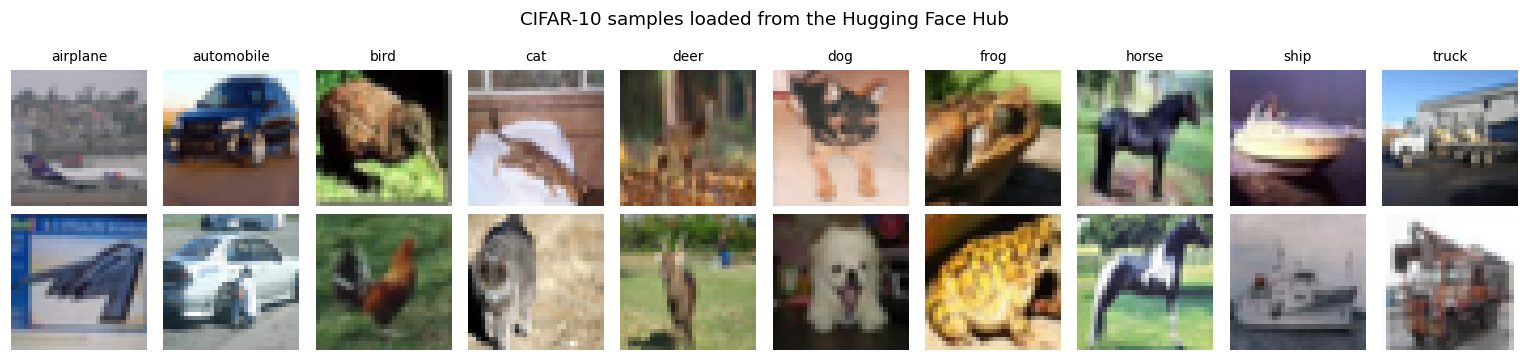

In [9]:
def to_numpy(split):
    X = np.stack([np.asarray(im.convert('RGB')) for im in ds[split][IMG_COL]])
    y = np.array(ds[split]['label'], dtype=np.int64)
    return X, y

X_train_u8, y_train_np = to_numpy('train')
X_test_u8,  y_test_np  = to_numpy('test')
print('train:', X_train_u8.shape, X_train_u8.dtype, '| test:', X_test_u8.shape)
print('pixel range:', X_train_u8.min(), '-', X_train_u8.max())

# class balance
cnt = pd.DataFrame({'class': CLASSES, 'train': np.bincount(y_train_np), 'test': np.bincount(y_test_np)}).set_index('class')
display(cnt.T)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for c in range(10):
    idx = np.where(y_train_np == c)[0][:2]
    for r, i in enumerate(idx):
        axes[r, c].imshow(X_train_u8[i]); axes[r, c].axis('off')
        if r == 0: axes[r, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle('CIFAR-10 samples loaded from the Hugging Face Hub'); plt.tight_layout(); plt.show()

# Part B: Convolution and Max-Pooling in NumPy
## B.1 The convolution operation
In a CNN, a **convolutional layer** slides a small learnable **kernel** (filter) over the input and computes a dot-product at every position. (Strictly, deep-learning libraries implement **cross-correlation**, with no kernel flip; we do the same.)

For an input of size $n$, kernel size $k$, padding $p$ and stride $s$ the output size along each spatial dimension is

$$ n_{out} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1 $$

For a multi-channel layer: input $(N, C_{in}, H, W)$, weights $(C_{out}, C_{in}, k_h, k_w)$, bias $(C_{out})$ → output $(N, C_{out}, H_{out}, W_{out})$ with

$$ y[n, f, i, j] = b_f + \sum_{c}\sum_{u}\sum_{v} x_{pad}[n, c, i\cdot s + u,\; j\cdot s + v]\; w[f, c, u, v] $$

We first write a **naive loop version** (single channel) to make the definition explicit, then a **vectorised version** (using `sliding_window_view` + `einsum`) for the full multi-channel case.

In [10]:
def conv_out_size(n, k, s=1, p=0):
    return (n + 2 * p - k) // s + 1

# ---- (1) Naive, single-channel 2-D convolution (cross-correlation) with explicit loops ----
def conv2d_naive(x, kernel, stride=1, padding=0):
    H, W = x.shape; kh, kw = kernel.shape
    xp = np.pad(x, padding)                                   # zero padding on all sides
    Ho, Wo = conv_out_size(H, kh, stride, padding), conv_out_size(W, kw, stride, padding)
    out = np.zeros((Ho, Wo))
    for i in range(Ho):
        for j in range(Wo):
            patch = xp[i * stride:i * stride + kh, j * stride:j * stride + kw]
            out[i, j] = np.sum(patch * kernel)
    return out

# ---- (2) Vectorised, batched, multi-channel convolution ----
def conv2d_np(x, w, b=None, stride=1, padding=0):
    # x: (N, C, H, W)   w: (F, C, kh, kw)   b: (F,)   ->   (N, F, Ho, Wo)
    N, C, H, W = x.shape; Fo, Cw, kh, kw = w.shape
    assert C == Cw, 'channel mismatch'
    xp = np.pad(x, ((0, 0), (0, 0), (padding, padding), (padding, padding)))
    win = sliding_window_view(xp, (kh, kw), axis=(2, 3))      # (N, C, H', W', kh, kw) - a view, no copy
    win = win[:, :, ::stride, ::stride]                       # apply the stride
    out = np.einsum('nchwuv,fcuv->nfhw', win, w, optimize=True)
    if b is not None: out = out + b[None, :, None, None]
    return out

# ---- sanity checks ----
rng = np.random.default_rng(0)
img = rng.normal(size=(12, 12)); ker = rng.normal(size=(3, 3))
for s, p in [(1, 0), (1, 1), (2, 0), (2, 1), (3, 2)]:
    a = conv2d_naive(img, ker, s, p)
    b_ = conv2d_np(img[None, None], ker[None, None], stride=s, padding=p)[0, 0]
    print(f'stride={s} pad={p}: naive {a.shape} vs vectorised {b_.shape} | max|diff| = {np.abs(a - b_).max():.2e}')

stride=1 pad=0: naive (10, 10) vs vectorised (10, 10) | max|diff| = 1.78e-15
stride=1 pad=1: naive (12, 12) vs vectorised (12, 12) | max|diff| = 1.78e-15
stride=2 pad=0: naive (5, 5) vs vectorised (5, 5) | max|diff| = 1.78e-15
stride=2 pad=1: naive (6, 6) vs vectorised (6, 6) | max|diff| = 8.88e-16
stride=3 pad=2: naive (5, 5) vs vectorised (5, 5) | max|diff| = 1.78e-15


### Verification against PyTorch
A from-scratch implementation should be checked against a trusted reference. We compare `conv2d_np` with `torch.nn.functional.conv2d` for random multi-channel inputs.

In [11]:
x = rng.normal(size=(4, 3, 16, 16)).astype(np.float32)
w = rng.normal(size=(8, 3, 5, 5)).astype(np.float32)
bias = rng.normal(size=(8,)).astype(np.float32)

rows = []
for s, p in [(1, 0), (1, 2), (2, 1), (2, 2), (3, 0)]:
    mine = conv2d_np(x, w, bias, stride=s, padding=p)
    ref = F.conv2d(torch.from_numpy(x), torch.from_numpy(w), torch.from_numpy(bias), stride=s, padding=p).numpy()
    rows.append({'stride': s, 'padding': p, 'output shape': mine.shape, 'max |diff|': float(np.abs(mine - ref).max()),
                 'match': np.allclose(mine, ref, atol=1e-4)})
pd.DataFrame(rows)

,stride,padding,output shape,max |diff|,match
0,1,0,"(4, 8, 12, 12)",0.000011,True
1,1,2,"(4, 8, 16, 16)",0.000011,True
2,2,1,"(4, 8, 7, 7)",0.000009,True
3,2,2,"(4, 8, 8, 8)",0.000009,True
4,3,0,"(4, 8, 4, 4)",0.000008,True


In [12]:
# Speed: naive loops vs vectorised on one 32x32 grayscale image
g = X_train_u8[0].mean(-1)
k3 = rng.normal(size=(3, 3))
t0 = time.time(); [conv2d_naive(g, k3, 1, 1) for _ in range(20)]; t_naive = (time.time() - t0) / 20
t0 = time.time(); [conv2d_np(g[None, None], k3[None, None], padding=1) for _ in range(20)]; t_vec = (time.time() - t0) / 20
print(f'naive loops : {t_naive * 1e3:7.3f} ms / image\nvectorised  : {t_vec * 1e3:7.3f} ms / image  ({t_naive / t_vec:.0f}x faster)')

naive loops :  10.535 ms / image
vectorised  :   0.389 ms / image  (27x faster)


## B.2 Hand-crafted kernels: what does a filter "see"?
A CNN *learns* its kernels, but classical image processing uses fixed ones. Applying them to a CIFAR image shows what a convolution computes: weighted local sums that detect edges, blur noise, etc.

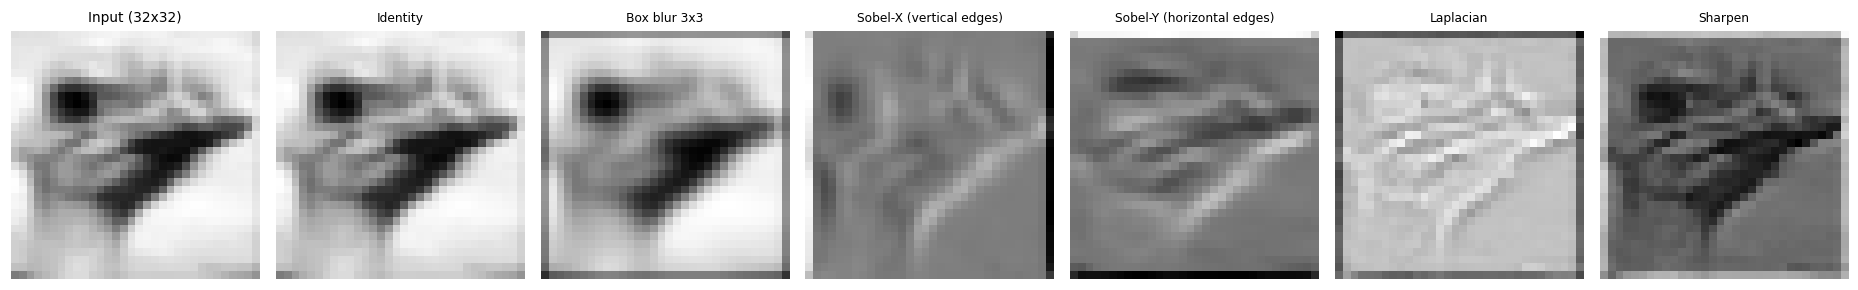

In [13]:
gray = X_train_u8[7].astype(float).mean(-1)          # one CIFAR image, grayscale (32x32)

KERNELS = {
    'Identity':       np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], float),
    'Box blur 3x3':   np.ones((3, 3)) / 9,
    'Sobel-X (vertical edges)':   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    'Sobel-Y (horizontal edges)': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
    'Laplacian':      np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float),
    'Sharpen':        np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
}
fig, axes = plt.subplots(1, len(KERNELS) + 1, figsize=(17, 3))
axes[0].imshow(gray, cmap='gray'); axes[0].set_title('Input (32x32)', fontsize=9); axes[0].axis('off')
for ax, (name, k) in zip(axes[1:], KERNELS.items()):
    out = conv2d_naive(gray, k, stride=1, padding=1)
    ax.imshow(out, cmap='gray'); ax.set_title(name, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## B.3 Max-pooling
**Max-pooling** slides a window over each channel independently and keeps only the **maximum** value. It has **no learnable parameters**; it

* **down-samples** the feature map (reduces computation and memory),
* provides **small translation invariance** (a feature that moves by a pixel inside the window still produces the same max),
* enlarges the receptive field of later layers.

Output size uses the same formula: $\lfloor (n + 2p - k)/s \rfloor + 1$; the default stride equals the window size. Padding for max-pooling uses $-\infty$ so padded cells can never be selected.

In [14]:
def maxpool2d_np(x, size=2, stride=None, padding=0):
    # x: (N, C, H, W)
    stride = stride or size
    if padding:
        x = np.pad(x, ((0, 0), (0, 0), (padding, padding), (padding, padding)), constant_values=-np.inf)
    win = sliding_window_view(x, (size, size), axis=(2, 3))[:, :, ::stride, ::stride]   # (N, C, Ho, Wo, size, size)
    return win.max(axis=(-2, -1))

# ---- worked example ----
m = np.array([[1, 3, 2, 1],
              [4, 6, 5, 2],
              [7, 8, 1, 0],
              [3, 2, 9, 4]], float)
print('Input 4x4:\n', m)
print('\nMax-pool 2x2, stride 2:\n', maxpool2d_np(m[None, None], 2)[0, 0])
print('\nMax-pool 2x2, stride 1 (overlapping):\n', maxpool2d_np(m[None, None], 2, 1)[0, 0])

# ---- verify against PyTorch ----
xt = rng.normal(size=(4, 6, 15, 15)).astype(np.float32)
rows = []
for size, stride, pad in [(2, None, 0), (3, 2, 0), (3, 2, 1), (2, 1, 0), (4, 4, 0)]:
    mine = maxpool2d_np(xt, size, stride, pad)
    ref = F.max_pool2d(torch.from_numpy(xt), size, stride or size, pad).numpy()
    rows.append({'size': size, 'stride': stride or size, 'padding': pad, 'output shape': mine.shape,
                 'match': bool(np.allclose(mine, ref))})
pd.DataFrame(rows)

Input 4x4:
 [[1. 3. 2. 1.]
 [4. 6. 5. 2.]
 [7. 8. 1. 0.]
 [3. 2. 9. 4.]]

Max-pool 2x2, stride 2:
 [[6. 5.]
 [8. 9.]]

Max-pool 2x2, stride 1 (overlapping):
 [[6. 6. 5.]
 [8. 8. 5.]
 [8. 9. 9.]]


,size,stride,padding,output shape,match
0,2,2,0,"(4, 6, 7, 7)",True
1,3,2,0,"(4, 6, 7, 7)",True
2,3,2,1,"(4, 6, 8, 8)",True
3,2,1,0,"(4, 6, 14, 14)",True
4,4,4,0,"(4, 6, 3, 3)",True


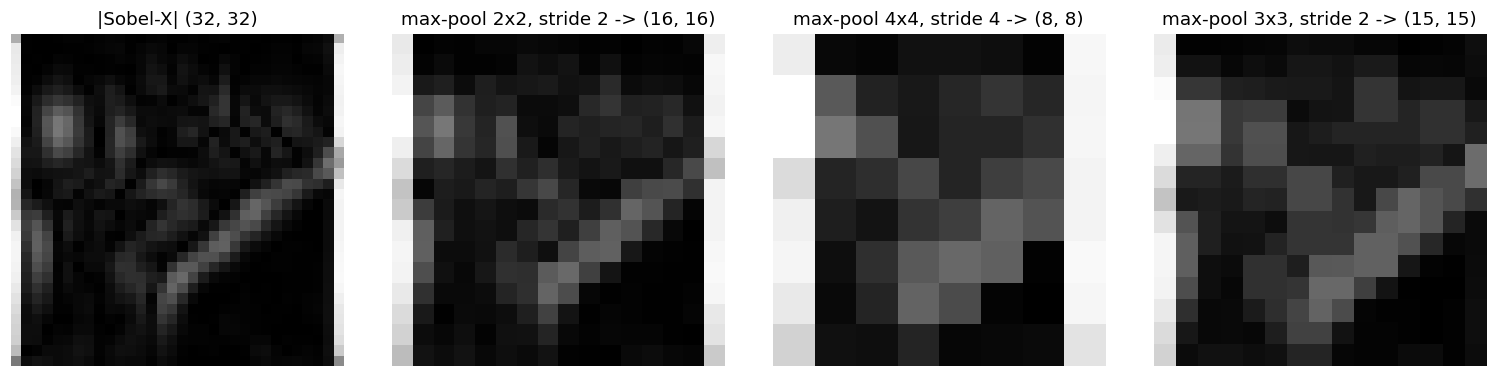

Mean abs difference after 1-pixel shift: before pooling = 71.81, after 2x2 max-pool = 64.24


In [15]:
# Visual: conv (Sobel-X) followed by max-pooling with different windows
edge = conv2d_naive(gray, KERNELS['Sobel-X (vertical edges)'], 1, 1)
edge_abs = np.abs(edge)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
axes[0].imshow(edge_abs, cmap='gray'); axes[0].set_title(f'|Sobel-X| {edge_abs.shape}')
for ax, (sz, st) in zip(axes[1:], [(2, 2), (4, 4), (3, 2)]):
    p_ = maxpool2d_np(edge_abs[None, None], sz, st)[0, 0]
    ax.imshow(p_, cmap='gray', interpolation='nearest'); ax.set_title(f'max-pool {sz}x{sz}, stride {st} -> {p_.shape}')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

# Small demo of translation tolerance: shift the image by 1 pixel and compare feature maps
shifted = np.roll(edge_abs, 1, axis=1)
d_before = np.abs(edge_abs - shifted).mean()
d_after = np.abs(maxpool2d_np(edge_abs[None, None], 2)[0, 0] - maxpool2d_np(shifted[None, None], 2)[0, 0]).mean()
print(f'Mean abs difference after 1-pixel shift: before pooling = {d_before:.2f}, after 2x2 max-pool = {d_after:.2f}')

# Part C: Exploring Kernel Size, Stride and Padding
We use our NumPy implementation to study each hyper-parameter **one at a time**.

| Hyper-parameter | Effect |
|---|---|
| **Kernel size** *k* | bigger → larger receptive field, more parameters (k²·C_in·C_out) and compute; smoother/more global features |
| **Stride** *s* | bigger → smaller output (≈ n/s), less compute, but information (resolution) is skipped |
| **Padding** *p* | zero-border keeps spatial size ("same" when p=(k−1)/2 for odd k, s=1) and lets border pixels contribute fully; no padding ("valid") shrinks the map by k−1 |

## C.1 Output-size table

In [16]:
rows = []
for n in (32,):
    for k in (1, 3, 5, 7):
        for s in (1, 2):
            for p in (0, (k - 1) // 2):
                rows.append({'input n': n, 'kernel k': k, 'stride s': s, 'padding p': p,
                             'output size': conv_out_size(n, k, s, p),
                             'params (C_in=3, C_out=16)': k * k * 3 * 16 + 16})
tbl = pd.DataFrame(rows)
display(tbl.head(16))

# check the formula against the implementation for every combination
ok = all(conv2d_np(np.zeros((1, 1, r['input n'], r['input n'])), np.zeros((1, 1, r['kernel k'], r['kernel k'])),
                   stride=r['stride s'], padding=r['padding p']).shape[-1] == r['output size'] for r in rows)
print('Formula matches implementation for all', len(rows), 'combinations:', ok)

,input n,kernel k,stride s,padding p,output size,"params (C_in=3, C_out=16)"
0,32,1,1,0,32,64
1,32,1,1,0,32,64
2,32,1,2,0,16,64
3,32,1,2,0,16,64
4,32,3,1,0,30,448
5,32,3,1,1,32,448
6,32,3,2,0,15,448
7,32,3,2,1,16,448
8,32,5,1,0,28,1216
9,32,5,1,2,32,1216


Formula matches implementation for all 16 combinations: True


## C.2 Kernel size
Same filter type (a box/average blur) at sizes 3, 5, 9, 15 on the same image, with no padding. Larger kernels blur more (wider neighbourhood) and shrink the output more.

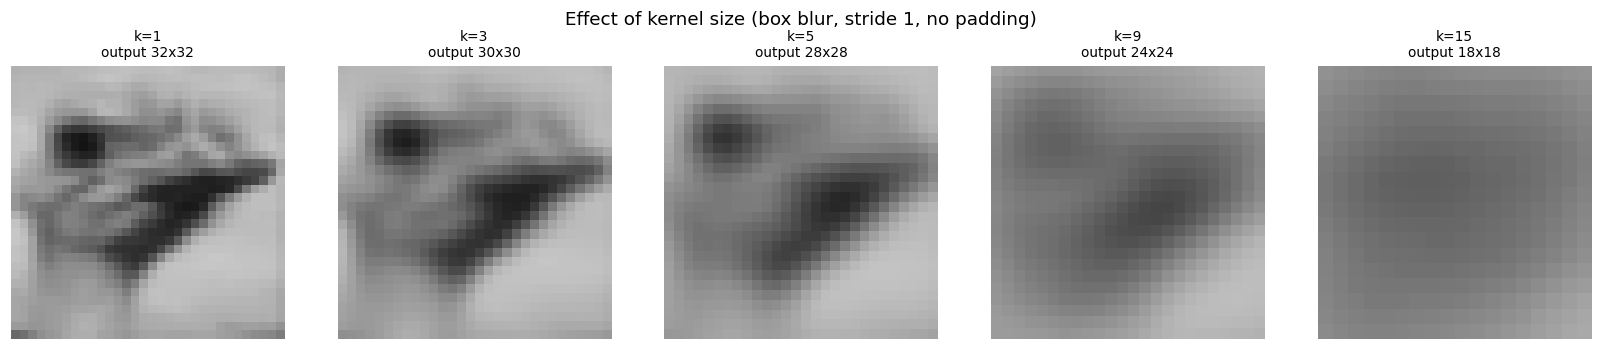

one 5x5 conv    : 25 weights per (in,out) channel pair
two 3x3 convs   : 18 weights per (in,out) channel pair
one 7x7 conv    : 49 weights per (in,out) channel pair
three 3x3 convs : 27 weights per (in,out) channel pair


In [17]:
sizes = [1, 3, 5, 9, 15]
fig, axes = plt.subplots(1, len(sizes), figsize=(15, 3.2))
for ax, k in zip(axes, sizes):
    out = conv2d_np(gray[None, None], (np.ones((1, 1, k, k)) / k ** 2), padding=0)[0, 0]
    ax.imshow(out, cmap='gray', interpolation='nearest', vmin=0, vmax=255); ax.set_title(f'k={k}\noutput {out.shape[0]}x{out.shape[1]}', fontsize=9); ax.axis('off')
plt.suptitle('Effect of kernel size (box blur, stride 1, no padding)'); plt.tight_layout(); plt.show()

# Receptive field of stacked 3x3 convolutions vs. one big kernel: two 3x3 = one 5x5 field with fewer parameters
for name, params in [('one 5x5 conv', 5 * 5), ('two 3x3 convs', 2 * 3 * 3), ('one 7x7 conv', 7 * 7), ('three 3x3 convs', 3 * 3 * 3)]:
    print(f'{name:16s}: {params} weights per (in,out) channel pair')

## C.3 Stride
Sobel-X applied with strides 1, 2, 4, 8. Larger strides evaluate the filter at fewer positions, so the output is a **down-sampled** version and fine detail is lost.

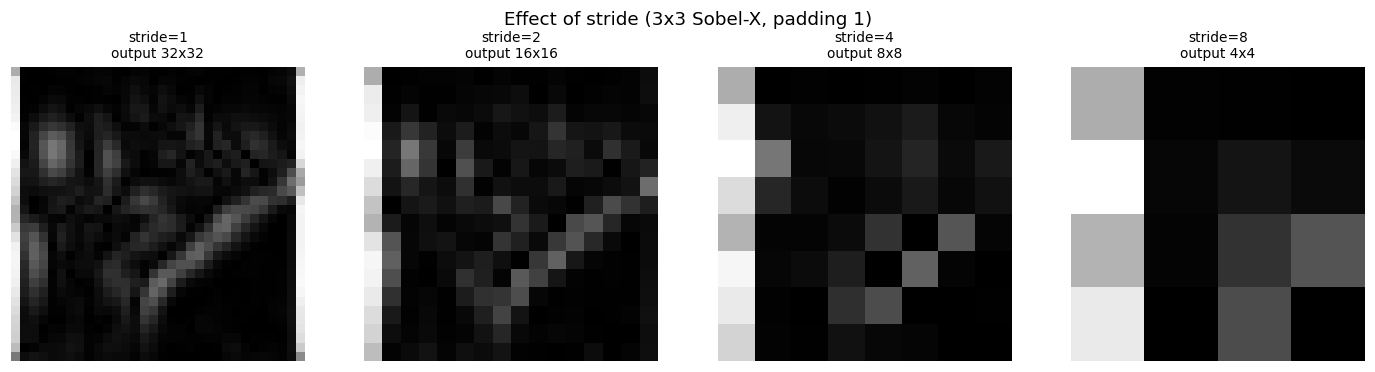

In [18]:
strides = [1, 2, 4, 8]
sob = KERNELS['Sobel-X (vertical edges)'][None, None]
fig, axes = plt.subplots(1, len(strides), figsize=(13, 3.4))
for ax, s in zip(axes, strides):
    out = np.abs(conv2d_np(gray[None, None], sob, stride=s, padding=1)[0, 0])
    ax.imshow(out, cmap='gray', interpolation='nearest'); ax.set_title(f'stride={s}\noutput {out.shape[0]}x{out.shape[1]}', fontsize=9); ax.axis('off')
plt.suptitle('Effect of stride (3x3 Sobel-X, padding 1)'); plt.tight_layout(); plt.show()

## C.4 Padding
Padding choices for a 5×5 kernel on a 32×32 image: **valid** (p=0), **same** (p=2) and **full** (p=k−1=4). We also show how many times each border pixel is covered by a window, which explains why "valid" convolutions under-use the image border.

valid (p=0)    -> output 28x28
same (p=2)     -> output 32x32
full (p=4)     -> output 36x36


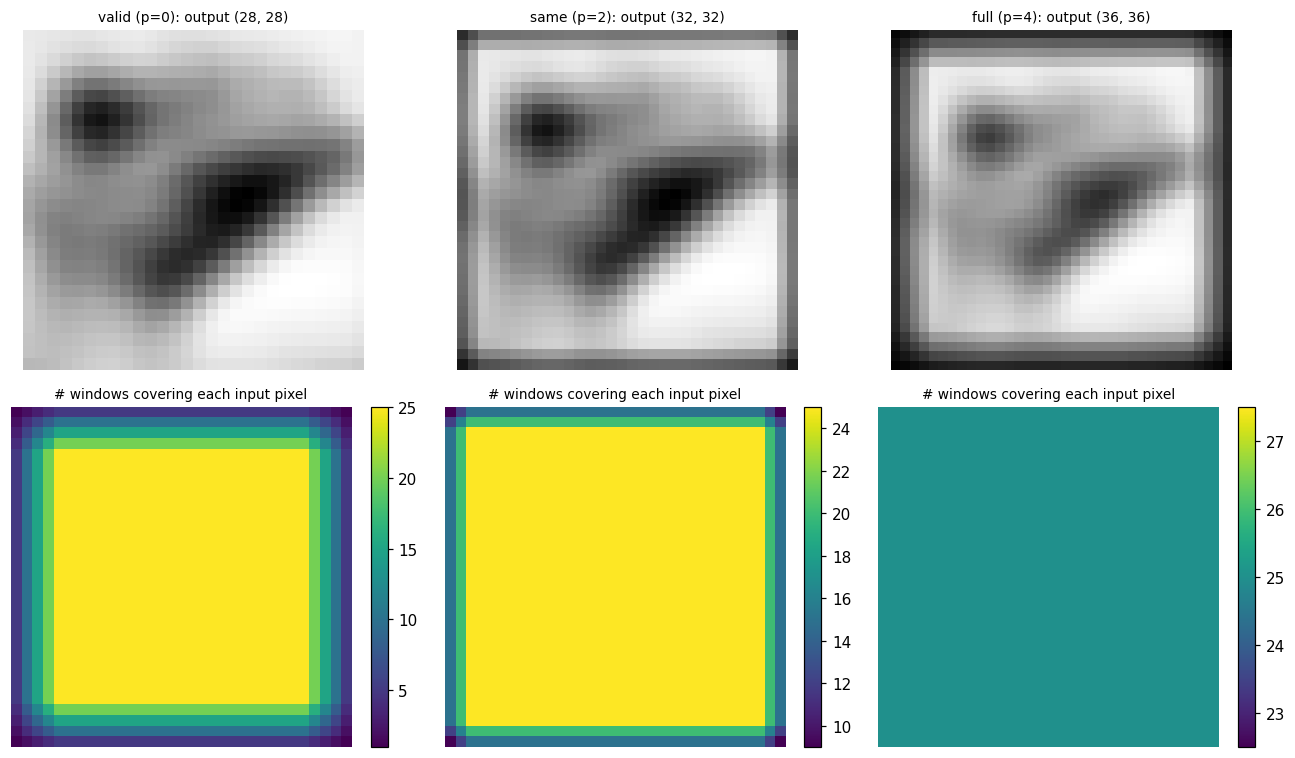

In [19]:
k = 5
modes = {'valid (p=0)': 0, 'same (p=2)': 2, 'full (p=4)': 4}
for name, p in modes.items():
    print(f'{name:14s} -> output {conv_out_size(32, k, 1, p)}x{conv_out_size(32, k, 1, p)}')

# coverage map: how many sliding windows include each input pixel (use an all-ones kernel on an all-ones image, then 'transpose' by counting)
def coverage(n, k, s, p):
    cov = np.zeros((n, n))
    for i in range(conv_out_size(n, k, s, p)):
        for j in range(conv_out_size(n, k, s, p)):
            r0, c0 = i * s - p, j * s - p
            cov[max(r0, 0):max(r0 + k, 0), max(c0, 0):max(c0 + k, 0)] += 1
    return cov

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for col, (name, p) in enumerate(modes.items()):
    out = np.abs(conv2d_np(gray[None, None], np.ones((1, 1, k, k)) / 25, padding=p)[0, 0])
    axes[0, col].imshow(out, cmap='gray', interpolation='nearest'); axes[0, col].set_title(f'{name}: output {out.shape}', fontsize=9); axes[0, col].axis('off')
    im = axes[1, col].imshow(coverage(32, k, 1, p), cmap='viridis'); axes[1, col].set_title('# windows covering each input pixel', fontsize=9); axes[1, col].axis('off')
    plt.colorbar(im, ax=axes[1, col], fraction=0.046)
plt.tight_layout(); plt.show()

### Observations (Part C)
* Output size follows $\lfloor (n+2p-k)/s \rfloor + 1$ exactly (verified against the implementation).
* **Kernel size** ↑ → stronger smoothing, bigger receptive field, but k² more weights. Stacking small 3×3 kernels reaches the same receptive field with fewer parameters and more non-linearities, which is why modern CNNs prefer them.
* **Stride** ↑ → resolution drops by ~s; it is a cheap way to down-sample but, unlike max-pooling, does not select the strongest response.
* **Padding** controls the shrinking of feature maps and border coverage: with "valid" convolutions the corner pixel is seen by one window only, whereas "same" padding reduces that imbalance.

# Part D: A Basic CNN for CIFAR-10
## D.1 Data preparation
* Pixel values scaled to [0,1] then **normalised** with the CIFAR-10 channel mean/std.
* Layout converted from `(N,H,W,C)` to PyTorch's `(N,C,H,W)`.
* Training set (50,000) is split into **45,000 train / 5,000 validation**; the official 10,000 images are kept as the **test set** (used once, at the end).
* All tensors are kept on the GPU for fast batching.

In [20]:
MEAN = np.array([0.4914, 0.4822, 0.4465], dtype=np.float32)
STD  = np.array([0.2470, 0.2435, 0.2616], dtype=np.float32)

def to_tensor(X_u8):
    x = (X_u8.astype(np.float32) / 255. - MEAN) / STD
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous()

rng_split = np.random.default_rng(42)
perm = rng_split.permutation(len(X_train_u8))
tr_idx, va_idx = perm[:45000], perm[45000:]

X_tr, y_tr = to_tensor(X_train_u8[tr_idx]).to(device), torch.from_numpy(y_train_np[tr_idx]).to(device)
X_va, y_va = to_tensor(X_train_u8[va_idx]).to(device), torch.from_numpy(y_train_np[va_idx]).to(device)
X_te, y_te = to_tensor(X_test_u8).to(device),           torch.from_numpy(y_test_np).to(device)
print('train', tuple(X_tr.shape), '| val', tuple(X_va.shape), '| test', tuple(X_te.shape))

train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32)


## D.2 Architecture
A **basic CNN**: three *Conv → ReLU → MaxPool* blocks followed by a classifier.

| Layer | Output shape | Parameters |
|---|---|---|
| Input | 3×32×32 | – |
| Conv 3×3, 32 filters, pad 1 → ReLU → MaxPool 2×2 | 32×16×16 | 896 |
| Conv 3×3, 64 filters, pad 1 → ReLU → MaxPool 2×2 | 64×8×8 | 18,496 |
| Conv 3×3, 128 filters, pad 1 → ReLU → MaxPool 2×2 | 128×4×4 | 73,856 |
| Flatten → Dropout(0.3) → Linear(2048→10) | 10 | 20,490 |

Convolution stages learn local patterns (edges → textures → parts); the max-pooling layers progressively reduce spatial size; the final linear layer maps the features to 10 class scores (logits). The loss is cross-entropy.

In [21]:
def make_cnn(k=3, padding=1, first_stride=1, channels=(32, 64, 128), dropout=0.3):
    layers, c = [], 3
    for i, ch in enumerate(channels):
        layers += [nn.Conv2d(c, ch, k, stride=first_stride if i == 0 else 1, padding=padding), nn.ReLU(), nn.MaxPool2d(2)]
        c = ch
    features = nn.Sequential(*layers)
    with torch.no_grad(): n_flat = features(torch.zeros(1, 3, 32, 32)).numel()      # infer flatten size automatically
    return nn.Sequential(features, nn.Flatten(), nn.Dropout(dropout), nn.Linear(n_flat, 10)).to(device)

model = make_cnn()
print(model)
print('\nTrainable parameters:', sum(p.numel() for p in model.parameters()))

# shape trace through the network
x = torch.zeros(1, 3, 32, 32, device=device)
for layer in model[0]:
    x = layer(x); print(f'{layer.__class__.__name__:10s} -> {tuple(x.shape[1:])}')

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=2048, out_features=10, bias=True)
)

Trainable parameters: 113738
Conv2d     -> (32, 32, 32)
ReLU       -> (32, 32, 32)
MaxPool2d  -> (32, 16, 16)
Conv2d     -> (64, 16, 16)
ReLU       -> (64, 16, 16)
MaxPool2d  -> (64, 8, 8)
Conv2d     -> (128, 8, 8)
ReLU       -> (128, 8, 8)
MaxPool2d  -> (128, 4, 4)


## D.3 Training utilities
The loop uses mini-batches of 128, **Adam** (lr = 1e-3) with **cosine learning-rate decay**, and a simple **random horizontal flip** augmentation (valid for natural images such as CIFAR-10).

In [22]:
@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)

def flip_aug(xb):
    mask = torch.rand(xb.size(0), device=xb.device) < 0.5
    xb = xb.clone(); xb[mask] = xb[mask].flip(3)
    return xb

def train_cnn(model, X, y, epochs=15, bs=128, lr=1e-3, augment=True, seed=0, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time']}
    gen = torch.Generator().manual_seed(seed); n, t0 = len(X), time.time()
    for ep in range(epochs):
        model.train(); order = torch.randperm(n, generator=gen).to(device); run_loss = 0.0; run_correct = 0
        for i in range(0, n, bs):
            idx = order[i:i + bs]; xb, yb = X[idx], y[idx]
            if augment: xb = flip_aug(xb)
            opt.zero_grad(set_to_none=True)
            out = model(xb); loss = F.cross_entropy(out, yb); loss.backward(); opt.step()
            run_loss += loss.item() * len(idx); run_correct += (out.argmax(1) == yb).sum().item()
        sched.step()
        vl, va = evaluate(model, X_va, y_va)
        hist['train_loss'].append(run_loss / n); hist['train_acc'].append(run_correct / n)
        hist['val_loss'].append(vl); hist['val_acc'].append(va); hist['time'].append(time.time() - t0)
        if verbose: print(f'epoch {ep + 1:2d}/{epochs} | train loss {run_loss / n:.3f} acc {run_correct / n:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time() - t0:5.1f}s')
    return hist

## D.4 Train the baseline CNN

In [23]:
set_seed(0)
model = make_cnn()
hist = train_cnn(model, X_tr, y_tr, epochs=15)
test_loss, test_acc = evaluate(model, X_te, y_te)
print(f'\nFINAL TEST accuracy = {test_acc:.4f}  (test loss {test_loss:.3f})')

epoch  1/15 | train loss 1.473 acc 0.469 | val loss 1.187 acc 0.590 |   2.7s
epoch  2/15 | train loss 1.105 acc 0.613 | val loss 0.968 acc 0.671 |   4.6s
epoch  3/15 | train loss 0.953 acc 0.670 | val loss 0.895 acc 0.685 |   6.5s
epoch  4/15 | train loss 0.863 acc 0.701 | val loss 0.795 acc 0.731 |   8.4s
epoch  5/15 | train loss 0.797 acc 0.724 | val loss 0.742 acc 0.748 |  10.2s
epoch  6/15 | train loss 0.749 acc 0.740 | val loss 0.750 acc 0.742 |  12.1s
epoch  7/15 | train loss 0.705 acc 0.757 | val loss 0.696 acc 0.759 |  14.1s
epoch  8/15 | train loss 0.670 acc 0.769 | val loss 0.672 acc 0.769 |  16.0s
epoch  9/15 | train loss 0.643 acc 0.779 | val loss 0.665 acc 0.769 |  18.0s
epoch 10/15 | train loss 0.614 acc 0.787 | val loss 0.638 acc 0.783 |  19.9s
epoch 11/15 | train loss 0.597 acc 0.794 | val loss 0.632 acc 0.786 |  22.1s
epoch 12/15 | train loss 0.577 acc 0.802 | val loss 0.621 acc 0.785 |  24.4s
epoch 13/15 | train loss 0.560 acc 0.808 | val loss 0.615 acc 0.787 |  26.3s

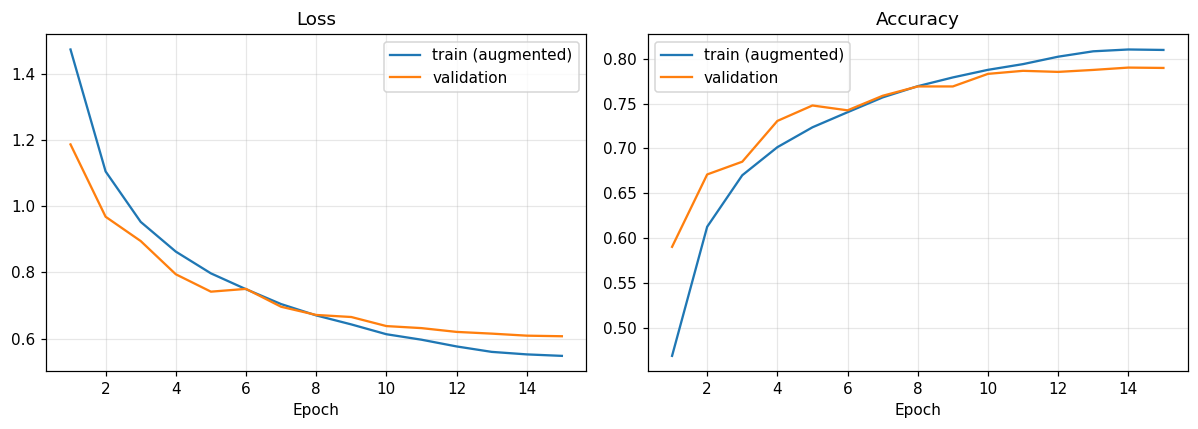

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); ep = range(1, len(hist['train_loss']) + 1)
ax[0].plot(ep, hist['train_loss'], label='train (augmented)'); ax[0].plot(ep, hist['val_loss'], label='validation'); ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, hist['train_acc'], label='train (augmented)'); ax[1].plot(ep, hist['val_acc'], label='validation'); ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## D.5 Evaluation: confusion matrix, per-class accuracy, errors

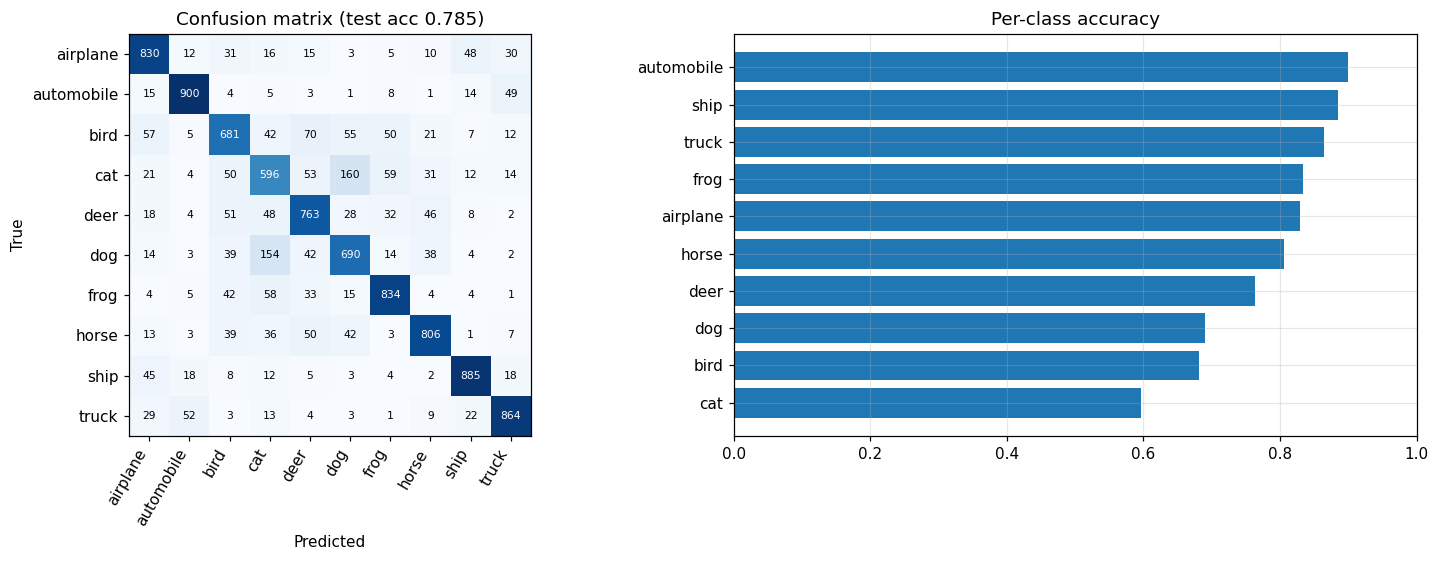

Most frequent confusions (true -> predicted):
     cat -> dog   : 160 images
     dog -> cat   : 154 images
    bird -> deer  : 70 images
     cat -> frog  : 59 images
    frog -> cat   : 58 images


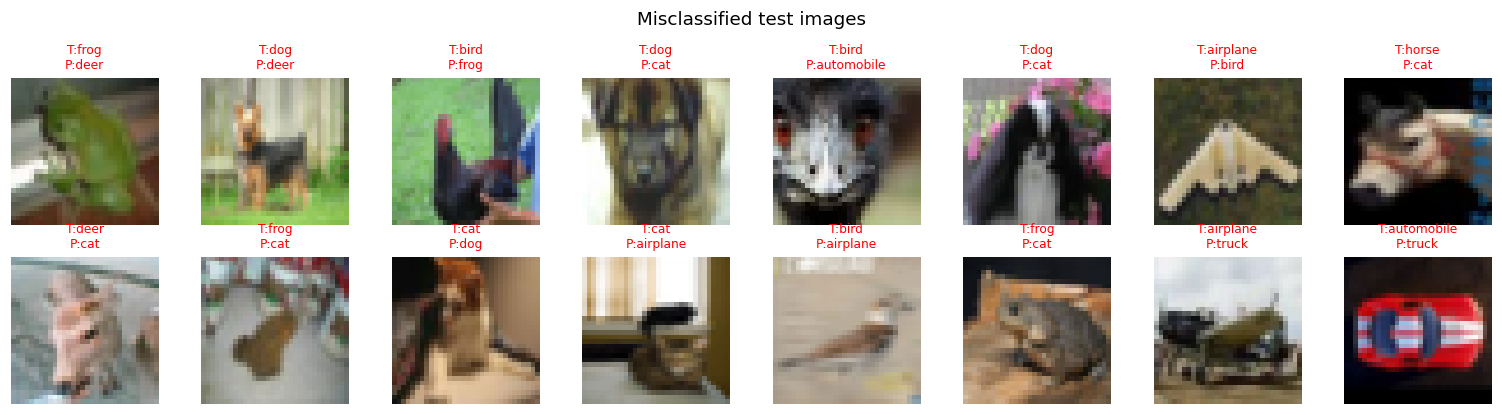

In [25]:
@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval(); return torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)]).cpu().numpy()

pred = predict(model, X_te); true = y_te.cpu().numpy()
cm = np.zeros((10, 10), int); np.add.at(cm, (true, pred), 1)
per_class = cm.diagonal() / cm.sum(1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
im = ax[0].imshow(cm, cmap='Blues'); ax[0].set_xticks(range(10)); ax[0].set_yticks(range(10))
ax[0].set_xticklabels(CLASSES, rotation=60, ha='right'); ax[0].set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10): ax[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('True'); ax[0].set_title(f'Confusion matrix (test acc {test_acc:.3f})')
order = np.argsort(per_class)
ax[1].barh(np.array(CLASSES)[order], per_class[order]); ax[1].set_title('Per-class accuracy'); ax[1].set_xlim(0, 1); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print('Most frequent confusions (true -> predicted):')
for t, p in top: print(f'  {CLASSES[t]:>6s} -> {CLASSES[p]:<6s}: {off[t, p]} images')

wrong = np.where(pred != true)[0][:16]
fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for a, i in zip(axes.ravel(), wrong):
    a.imshow(X_test_u8[i]); a.set_title(f'T:{CLASSES[true[i]]}\nP:{CLASSES[pred[i]]}', fontsize=8, color='red'); a.axis('off')
plt.suptitle('Misclassified test images'); plt.tight_layout(); plt.show()

## D.6 Looking inside the CNN: learned filters and feature maps
The first-layer kernels are 3×3×3 (RGB) patterns; typically a mix of colour blobs and oriented edges.

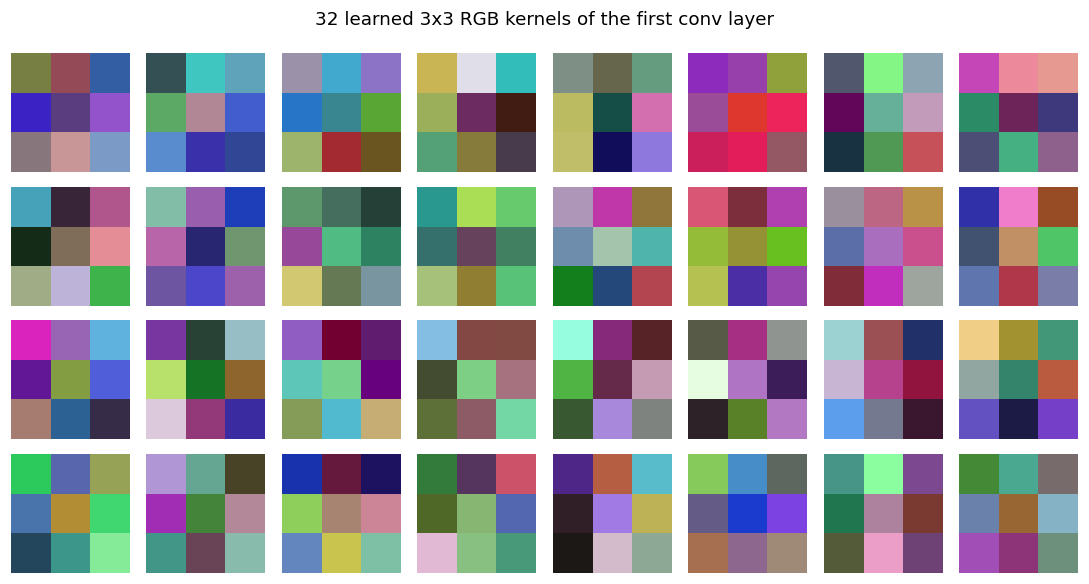

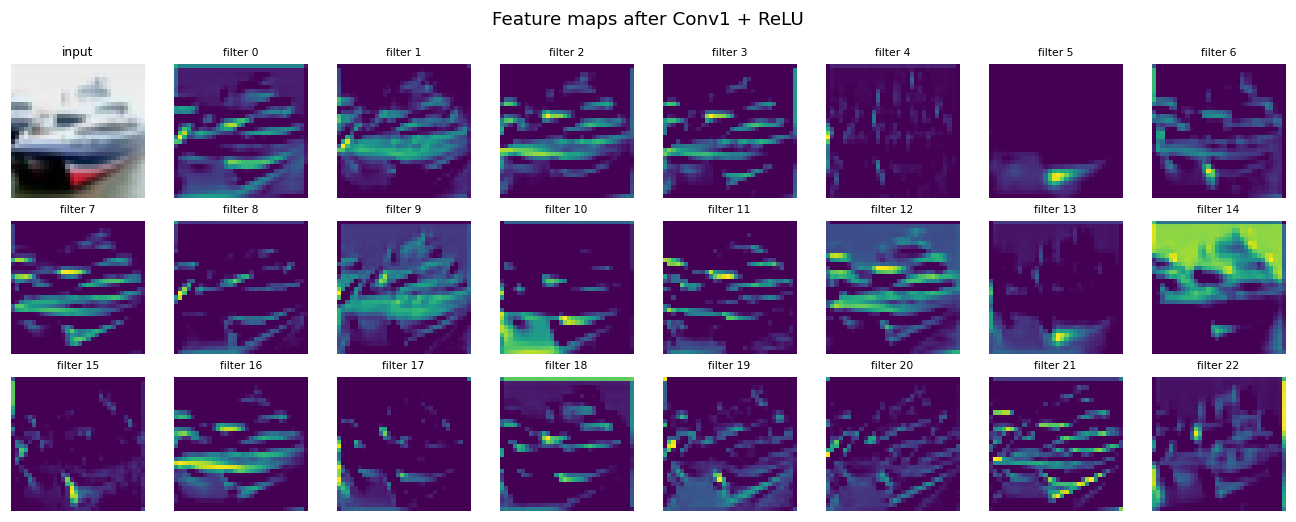

In [26]:
conv1 = model[0][0]
W1 = conv1.weight.detach().cpu().numpy()                  # (32, 3, 3, 3)
Wn = (W1 - W1.min()) / (W1.max() - W1.min())
fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
for a, f in zip(axes.ravel(), range(32)):
    a.imshow(Wn[f].transpose(1, 2, 0), interpolation='nearest'); a.axis('off')
plt.suptitle('32 learned 3x3 RGB kernels of the first conv layer'); plt.tight_layout(); plt.show()

# feature maps of one test image after conv1+ReLU
i = int(np.where(true == CLASSES.index('ship'))[0][0]) if 'ship' in CLASSES else 0
with torch.no_grad(): fmap = F.relu(conv1(X_te[i:i + 1]))[0].cpu().numpy()      # (32, 32, 32)
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
axes[0, 0].imshow(X_test_u8[i]); axes[0, 0].set_title('input', fontsize=8)
for a in axes.ravel(): a.axis('off')
for a, f in zip(axes.ravel()[1:], range(23)):
    a.imshow(fmap[f], cmap='viridis'); a.set_title(f'filter {f}', fontsize=7)
plt.suptitle('Feature maps after Conv1 + ReLU'); plt.tight_layout(); plt.show()

### Linking Parts B and D: reproduce the trained layer with our NumPy code
The ultimate test of our from-scratch operations: take the **trained weights** of the first conv layer and the first pooling stage, run them with `conv2d_np` and `maxpool2d_np`, and compare with the PyTorch model's output.

In [27]:
model.eval()
xi = X_te[:8].cpu().numpy()
w1, b1 = conv1.weight.detach().cpu().numpy(), conv1.bias.detach().cpu().numpy()

np_conv = conv2d_np(xi, w1, b1, stride=1, padding=1)
np_block = maxpool2d_np(np.maximum(np_conv, 0), size=2)                  # Conv -> ReLU -> MaxPool, entirely NumPy
with torch.no_grad(): torch_block = model[0][:3](X_te[:8]).cpu().numpy()   # first block of the PyTorch CNN

print('NumPy block output shape :', np_block.shape)
print('PyTorch block output shape:', torch_block.shape)
print('max |difference|          :', float(np.abs(np_block - torch_block).max()))
print('Match:', np.allclose(np_block, torch_block, atol=1e-4))

NumPy block output shape : (8, 32, 16, 16)
PyTorch block output shape: (8, 32, 16, 16)
max |difference|          : 0.0
Match: True


## D.7 Ablation: kernel size, padding and stride *inside* the CNN
Part C studied these on a single image; here we measure their effect on **accuracy, parameters and time**. To keep the study quick, every variant trains on a **20,000-image subset for 8 epochs** with identical seed, optimizer and schedule. Only the listed hyper-parameter changes (stride is applied to the first conv layer only).

In [28]:
CFGS = {
    'k=3, pad=1, stride=1 (baseline)': dict(k=3, padding=1, first_stride=1),
    'k=5, pad=2, stride=1':            dict(k=5, padding=2, first_stride=1),
    'k=7, pad=3, stride=1':            dict(k=7, padding=3, first_stride=1),
    'k=3, pad=0 ("valid")':            dict(k=3, padding=0, first_stride=1),
    'k=3, pad=1, stride=2 (1st layer)': dict(k=3, padding=1, first_stride=2),
}
Xs, ys = X_tr[:20000], y_tr[:20000]
rows = []
for name, cfg in CFGS.items():
    set_seed(0); m = make_cnn(**cfg)
    h = train_cnn(m, Xs, ys, epochs=8, verbose=False)
    tl, ta = evaluate(m, X_te, y_te)
    rows.append({'Config': name, 'Params': sum(p.numel() for p in m.parameters()),
                 'Final val acc': h['val_acc'][-1], 'Test acc': ta, 'Time (s)': h['time'][-1]})
    print('done:', name)
abl = pd.DataFrame(rows).set_index('Config').round(4)
abl

done: k=3, pad=1, stride=1 (baseline)
done: k=5, pad=2, stride=1
done: k=7, pad=3, stride=1
done: k=3, pad=0 ("valid")
done: k=3, pad=1, stride=2 (1st layer)


,Params,Final val acc,Test acc,Time (s)
Config,,,,
"k=3, pad=1, stride=1 (baseline)",113738,0.6942,0.6943,7.3102
"k=5, pad=2, stride=1",279114,0.7184,0.7147,15.3920
"k=7, pad=3, stride=1",527178,0.7108,0.6993,25.7534
"k=3, pad=0 (""valid"")",98378,0.6270,0.6339,6.3382
"k=3, pad=1, stride=2 (1st layer)",98378,0.6232,0.6225,3.9248


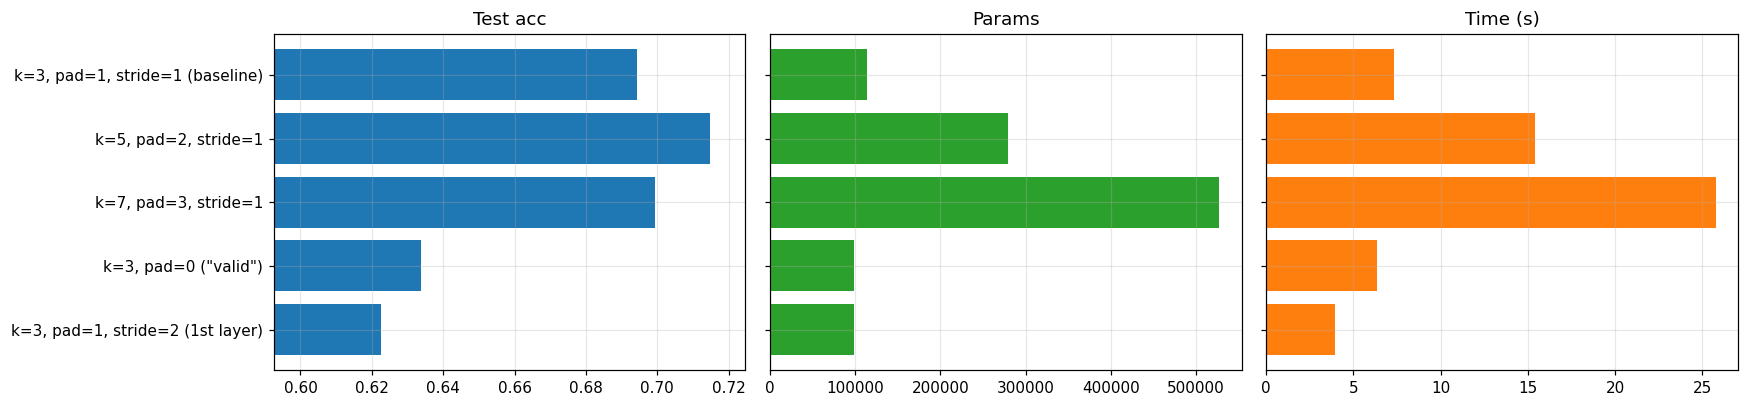

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col, c in zip(ax, ['Test acc', 'Params', 'Time (s)'], ['tab:blue', 'tab:green', 'tab:orange']):
    a.barh(abl.index, abl[col], color=c); a.set_title(col); a.invert_yaxis(); a.grid(alpha=.3)
    if col != 'Test acc': a.set_yticklabels([])
ax[0].set_xlim(abl['Test acc'].min() - 0.03, abl['Test acc'].max() + 0.01)
plt.tight_layout(); plt.show()

### Observations (Part D)
*Fill in with your own numbers; typical patterns are listed as a guide.*
* The baseline 3-block CNN reaches roughly **75–80 % test accuracy** in 15 epochs, far above the 10 % chance level, with most confusion between visually similar animals (cat ↔ dog, deer ↔ horse) and vehicles (automobile ↔ truck).
* **Padding:** using "same" padding keeps more spatial information and usually beats "valid" slightly, as border pixels are used fully and maps do not shrink so fast.
* **Kernel size:** 5×5 and 7×7 kernels have many more parameters and take longer; the gain over stacked 3×3 layers is typically small or negative.
* **Stride 2** in the first layer cuts compute (feature maps 4× smaller) but usually costs some accuracy, because fine detail is discarded early.
* Differences of ≲1 % from one seed should be treated as noise.

# Part E: Documenting the Model with a Model Card
Having trained a model, good practice is to publish it **with a model card**. We create one using `huggingface_hub`'s `ModelCard` (YAML metadata + Markdown) from our actual results, and save the weights next to it. Uploading is optional and needs a token.

In [30]:
from huggingface_hub import ModelCardData, ModelCard
import json, os

os.makedirs('cifar10-basic-cnn', exist_ok=True)
torch.save(model.state_dict(), 'cifar10-basic-cnn/pytorch_model.pt')

meta = ModelCardData(language='en', license='mit', library_name='pytorch', tags=['image-classification', 'cnn', 'cifar10', 'education'],
                     datasets=['uoft-cs/cifar10'], metrics=['accuracy'], pipeline_tag='image-classification')

body = f"""
# Basic CNN for CIFAR-10

## Model description
A small convolutional network (3 x [Conv3x3 -> ReLU -> MaxPool2x2] with 32/64/128 filters, then Dropout(0.3) and a linear classifier).
Trainable parameters: {sum(p.numel() for p in model.parameters()):,}. Created for a university self-learning lab (not a production model).

## Intended uses & limitations
* Intended for teaching: illustrating convolution, pooling, and training of a small CNN.
* **Not** intended for real-world decision making. Input is limited to 32x32 RGB images of the 10 CIFAR-10 classes; it will not generalise to other image types or higher resolutions.

## Training data
CIFAR-10 (`uoft-cs/cifar10`): 45,000 training images and 5,000 validation images (random split of the official training set). Per-channel mean/std normalisation; random horizontal flip augmentation.

## Training procedure
* Optimizer: Adam, lr = 1e-3 with cosine decay, batch size 128, 15 epochs
* Loss: cross-entropy; seed 0; framework: PyTorch {torch.__version__}

## Evaluation
Evaluated once on the official 10,000-image test set.

| Metric | Value |
|---|---|
| Test accuracy | {test_acc:.4f} |

Per-class test accuracy:

| Class | Accuracy |
|---|---|
""" + "\n".join(f"| {c} | {a:.3f} |" for c, a in zip(CLASSES, per_class)) + """

## Bias, risks and limitations
CIFAR-10 contains small, low-resolution, centred images with a limited set of categories, so performance does not reflect real-world conditions (clutter, lighting, camera differences). The model confuses visually similar classes (e.g. cat/dog).

## How to use
```python
model = make_cnn(); model.load_state_dict(torch.load('pytorch_model.pt')); model.eval()
# input: float tensor (N, 3, 32, 32), normalised with CIFAR-10 mean/std
```
"""
card = ModelCard(f'---\n{meta.to_yaml()}\n---\n{body}')
card.save('cifar10-basic-cnn/README.md')
print(open('cifar10-basic-cnn/README.md').read()[:2500])

---
datasets:
- uoft-cs/cifar10
language: en
library_name: pytorch
license: mit
metrics:
- accuracy
pipeline_tag: image-classification
tags:
- image-classification
- cnn
- cifar10
- education
---

# Basic CNN for CIFAR-10

## Model description
A small convolutional network (3 x [Conv3x3 -> ReLU -> MaxPool2x2] with 32/64/128 filters, then Dropout(0.3) and a linear classifier).
Trainable parameters: 113,738. Created for a university self-learning lab (not a production model).

## Intended uses & limitations
* Intended for teaching: illustrating convolution, pooling, and training of a small CNN.
* **Not** intended for real-world decision making. Input is limited to 32x32 RGB images of the 10 CIFAR-10 classes; it will not generalise to other image types or higher resolutions.

## Training data
CIFAR-10 (`uoft-cs/cifar10`): 45,000 training images and 5,000 validation images (random split of the official training set). Per-channel mean/std normalisation; random horizontal flip augmentation.


In [31]:
# ---- OPTIONAL: publish to the Hub (needs a free account + a WRITE token). Uncomment to use. ----
# from huggingface_hub import notebook_login
# notebook_login()                                   # paste your token
# repo_id = 'YOUR-USERNAME/cifar10-basic-cnn'
# api.create_repo(repo_id, exist_ok=True)
# api.upload_folder(folder_path='cifar10-basic-cnn', repo_id=repo_id)
# print('Published at https://huggingface.co/' + repo_id)

# Re-reading the local card back as a ModelCard object:
c2 = ModelCard.load('cifar10-basic-cnn/README.md')
print('Parsed metadata:', c2.data.to_dict())

Parsed metadata: {'datasets': ['uoft-cs/cifar10'], 'language': 'en', 'library_name': 'pytorch', 'license': 'mit', 'metrics': ['accuracy'], 'pipeline_tag': 'image-classification', 'tags': ['image-classification', 'cnn', 'cifar10', 'education']}


# Summary & Conclusions
Complete this table with **your own** results.

| Topic | Key finding (write your result) |
|---|---|
| Hugging Face Hub | e.g. repos for models/datasets/spaces; read public repos without login; cards document usage and limits |
| Dataset loading | e.g. `load_dataset('uoft-cs/cifar10')` returned train (50,000) / test (10,000); features `img`, `label`; converted to NumPy `(N,32,32,3)` |
| NumPy convolution / pooling | e.g. vectorised version matched PyTorch with max error ___ and was ___× faster than loops |
| Kernel size | e.g. larger kernels blur more, shrink the map more and add k² parameters |
| Stride | e.g. stride s reduces each spatial dimension by ≈ s |
| Padding | e.g. "same" keeps 32×32; "valid" loses k−1 pixels per layer |
| CIFAR-10 CNN | e.g. test accuracy ___ ; best class ___ ; worst class ___ |
| Ablation | e.g. best config = ___ ; k=7 costs ___× more parameters for ___ accuracy change |

### Take-aways
1. The **Hub** is a one-stop place to find, version, document and share models and datasets; **cards** make them understandable and responsibly reusable.
2. Convolution and max-pooling are simple operations (sliding-window dot-products and maxima) governed by the formula ⌊(n+2p−k)/s⌋+1, and they can be implemented and *verified* from scratch.
3. **Kernel size, stride and padding** trade off receptive field, resolution, parameters and compute.
4. A small CNN with a handful of layers already performs far better than an MLP-type model on images because of **local connectivity and weight sharing**.

### Possible extensions
* Add **BatchNorm** and deeper blocks, random-crop augmentation, label smoothing, or a ResNet-style skip connection.
* Implement the **backward pass** of convolution and max-pooling in NumPy and train a tiny CNN purely in NumPy.
* Fine-tune a pre-trained model from the Hub (e.g. `microsoft/resnet-18`) on CIFAR-10 and compare with this baseline.